# Actividad Individual 3 — Regresión Logística Binaria

**Contexto del problema**
El propósito de esta actividad es ayudar a una institución que quiere anticipar qué estudiantes tienen mayor riesgo de abandonar para activar estrategias de retención (tutorías, becas, seguimiento). Intervenir tiene un costo, no hacerlo también.

Es importante tomar en cuenta el tipo de error y el costo:

**Falso Positivo** (Intervenimos a un estudiante que no iba a abandonar) =  **\$10,000**

**Falso Negativo**(No intervenimos a un estudiante que sí abandona) = **\$80,000** 

El reto es elegir el umbral de decisión que **minimice el costo total**, no el que maximice la exactitud.

## Paso 0 — Importar librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    roc_curve, roc_auc_score, precision_recall_curve,
    average_precision_score, precision_score, recall_score, f1_score
)



## Paso 1 — Cargar los datos

In [2]:
data = pd.read_csv("Retention_Tec_versión clase_v2.csv")
data.head()

,Abandono,Gender,Age,High_School_GPA,Language_Level,Toefl
0,0,1,26,87.00,8,637
1,1,1,24,75.12,7,590
2,1,1,24,84.57,7,593
3,1,0,23,88.83,8,617
4,1,1,23,85.14,8,613


In [3]:
print("Dimensiones del dataset:", data.shape)

Dimensiones del dataset: (6620, 6)


## Paso 2 — Análisis exploratorio de datos (EDA)

Antes de modelar necesitamos entender qué tenemos: tipos de variables, distribuciones, valores faltantes, duplicados y cómo se relaciona cada variable con el abandono.

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6620 entries, 0 to 6619
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Abandono         6620 non-null   int64  
 1   Gender           6620 non-null   int64  
 2   Age              6620 non-null   int64  
 3   High_School_GPA  6620 non-null   float64
 4   Language_Level   6620 non-null   int64  
 5   Toefl            6620 non-null   int64  
dtypes: float64(1), int64(5)
memory usage: 310.4 KB


In [5]:
data.describe()

,Abandono,Gender,Age,High_School_GPA,Language_Level,Toefl
count,6620.000000,6620.000000,6620.000000,6620.000000,6620.000000,6620.000000
mean,0.043505,0.535650,18.242145,86.630085,7.100000,585.959819
std,0.204005,0.498765,0.665880,5.780654,0.986064,42.906271
min,0.000000,0.000000,16.000000,59.133000,1.000000,398.000000
25%,0.000000,0.000000,18.000000,82.239500,7.000000,557.000000
50%,0.000000,1.000000,18.000000,86.870000,7.000000,587.000000
75%,0.000000,1.000000,19.000000,91.035500,8.000000,617.000000
max,1.000000,1.000000,26.000000,99.610000,8.000000,677.000000


### 2.1 Valores faltantes y duplicados

In [6]:
# Verificación de valores nulos por columna
print("Valores nulos por columna:")
print(data.isna().sum())
print()
print("Registros duplicados:", data.duplicated().sum())

Valores nulos por columna:
Abandono           0
Gender             0
Age                0
High_School_GPA    0
Language_Level     0
Toefl              0
dtype: int64

Registros duplicados: 51


### 2.2 Balance de clases — variable objetivo Abandono

In [7]:
print(data['Abandono'].value_counts())
print()
print(data['Abandono'].value_counts(normalize=True).round(3))

Abandono
0    6332
1     288
Name: count, dtype: int64

Abandono
0    0.956
1    0.044
Name: proportion, dtype: float64


C:\Users\hdzmi\AppData\Local\Temp\ipykernel_21680\468449569.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Abandono', data=data, palette=['steelblue', 'tomato'])


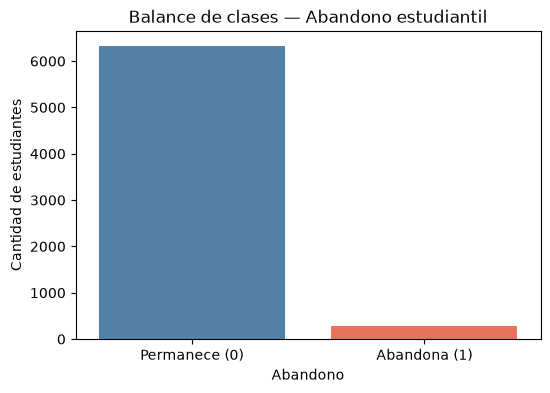

In [8]:
plt.figure(figsize=(6, 4))
plt.title("Balance de clases — Abandono estudiantil")
sns.countplot(x='Abandono', data=data, palette=['steelblue', 'tomato'])
plt.xticks([0, 1], ['Permanece (0)', 'Abandona (1)'])
plt.xlabel("Abandono")
plt.ylabel("Cantidad de estudiantes")
plt.show()

In [61]:
# Porcentaje exacto de abandono 
print(f"Tasa de abandono: {data['Abandono'].mean()*100:.1f}%")

Tasa de abandono: 4.4%


> **Nota:** Solo el **4.4 %** de los estudiantes abandona. Esto se llama **clase desbalanceada**.
> Consecuencia práctica: un modelo que siempre prediga "permanece" tendría accuracy del 95.6 %
> pero sería completamente inútil. Por eso priorizaremos métricas como AUC, Recall y **costo total**.

### 2.3 Distribución de variables numéricas

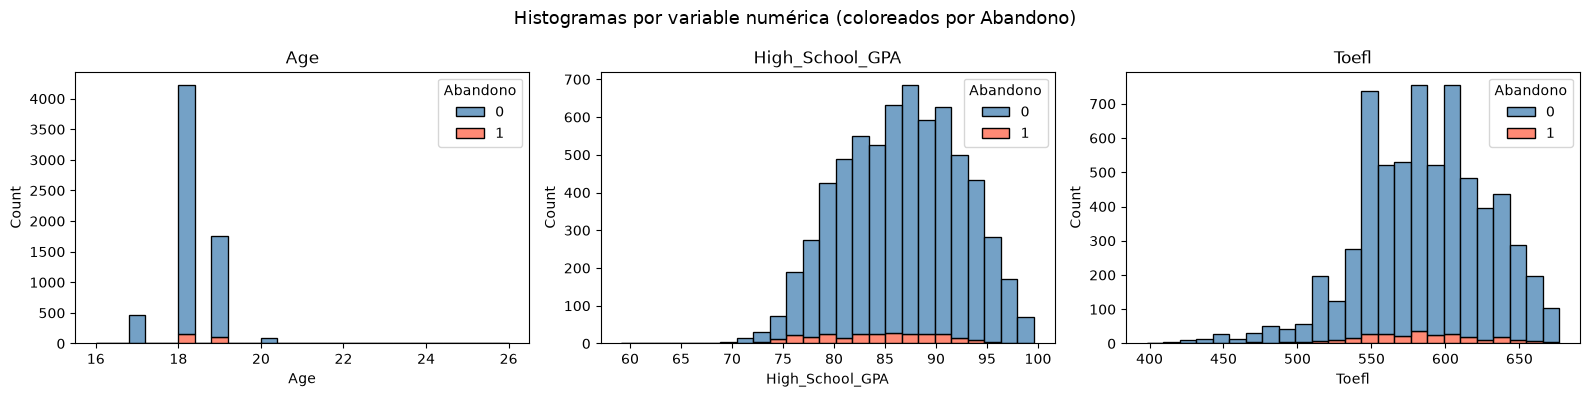

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("Histogramas por variable numérica (coloreados por Abandono)", fontsize=13)

for ax, col, color in zip(axes, ['Age', 'High_School_GPA', 'Toefl'],
                          ['royalblue', 'seagreen', 'darkorange']):
    sns.histplot(data=data, x=col, hue='Abandono', bins=25,
                 multiple='stack', palette=['steelblue', 'tomato'], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

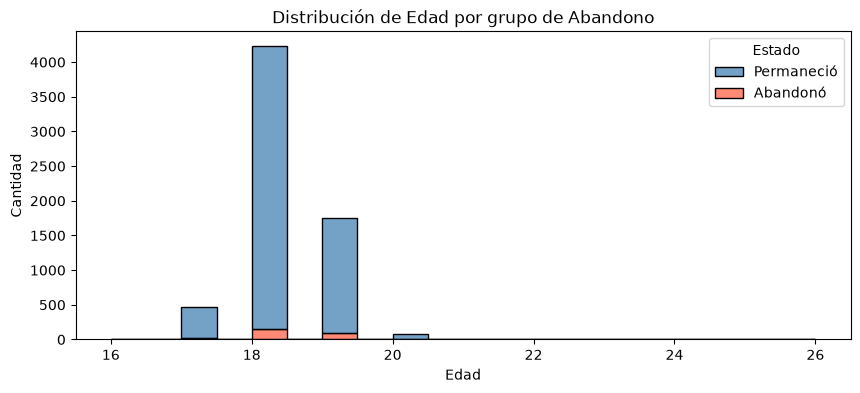

In [54]:
data['Estado'] = data['Abandono'].map({
    0: 'Permaneció',
    1: 'Abandonó'
})

plt.figure(figsize=(10, 4))
plt.title("Distribución de Edad por grupo de Abandono")

sns.histplot(
    data=data,
    x='Age',
    bins=20,
    hue='Estado',
    multiple='stack',
    palette=['steelblue', 'tomato']
)

plt.xlabel("Edad")
plt.ylabel("Cantidad")
plt.show()

C:\Users\hdzmi\AppData\Local\Temp\ipykernel_21680\4048004645.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Age', data=data, palette='rainbow')


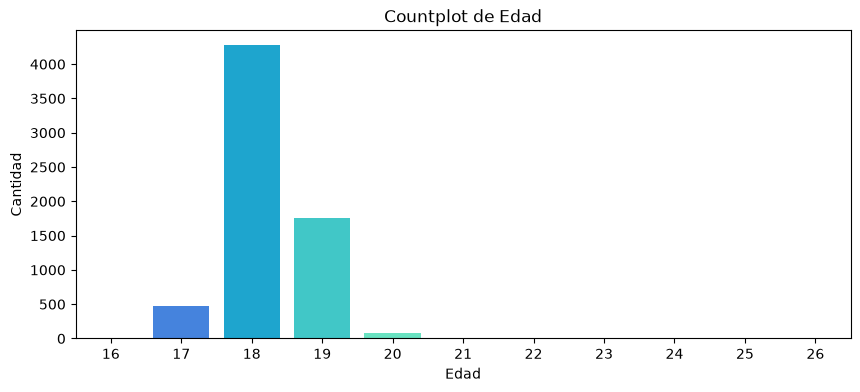

In [11]:
# Countplot de Age (equivalente al del maestro para Age en Titanic)
plt.figure(figsize=(10, 4))
plt.title("Countplot de Edad")
sns.countplot(x='Age', data=data, palette='rainbow')
plt.xlabel("Edad")
plt.ylabel("Cantidad")
plt.show()

### 2.4 Abandono según Género

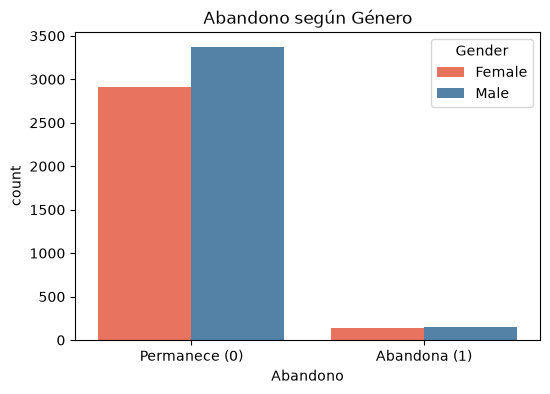

In [56]:
plt.figure(figsize=(6, 4))
plt.title("Abandono según Género")

sns.countplot(
    x='Abandono',
    data=data,
    hue='Gender',
    palette=['tomato', 'steelblue']
)

plt.xticks([0, 1], ['Permanece (0)', 'Abandona (1)'])
plt.legend(title='Gender', labels=['Female', 'Male'])

plt.show()

### 2.5 Abandono según Nivel de Inglés

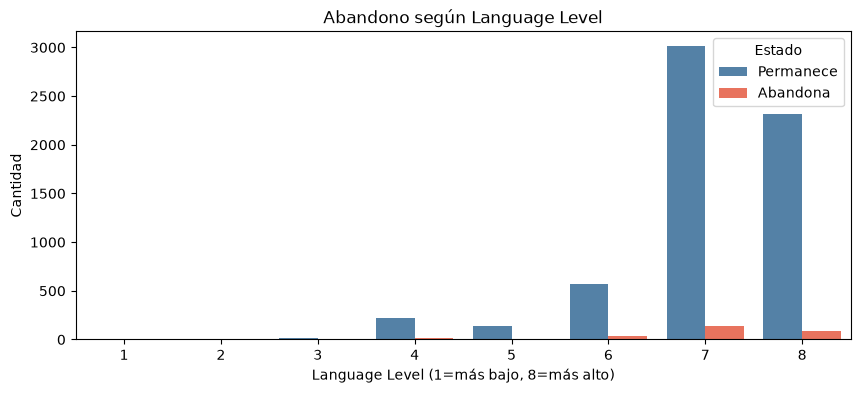

In [57]:
plt.figure(figsize=(10, 4))
plt.title("Abandono según Language Level")

ax = sns.countplot(
    x='Language_Level',
    data=data,
    hue='Abandono',
    palette=['steelblue', 'tomato']
)

# Cambiar etiquetas de la leyenda
legend = ax.get_legend()
if legend:
    legend.set_title('Estado')
    legend.texts[0].set_text('Permanece')
    legend.texts[1].set_text('Abandona')

plt.xlabel("Language Level (1=más bajo, 8=más alto)")
plt.ylabel("Cantidad")
plt.show()

In [14]:
# Tasa de abandono por nivel de inglés
print("Tasa de abandono por Language_Level:")
print(data.groupby('Language_Level')['Abandono'].mean().round(3))

Tasa de abandono por Language_Level:
Language_Level
1    0.000
2    0.000
3    0.105
4    0.061
5    0.063
6    0.061
7    0.044
8    0.036
Name: Abandono, dtype: float64


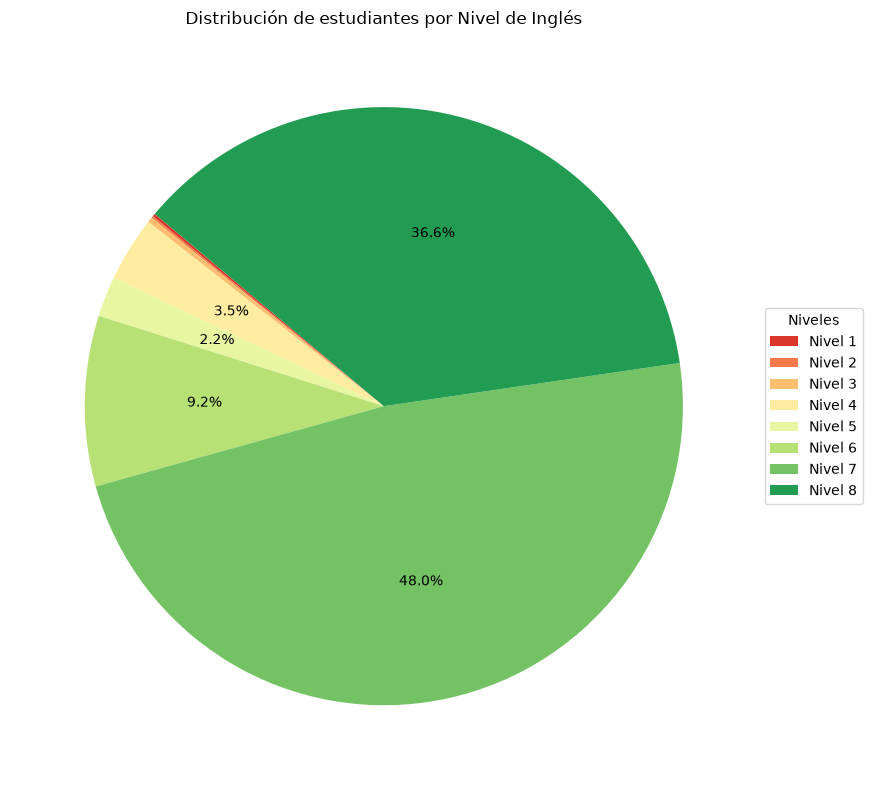

In [50]:
# Pie chart de distribución de Language Level (como Pclass en el ejemplo S6)
conteos = data['Language_Level'].value_counts().sort_index()

def porcentaje_visible(pct):
    return f'{pct:.1f}%' if pct >= 2 else ''

plt.figure(figsize=(10, 8))

wedges, texts, autotexts = plt.pie(
    conteos,
    autopct=porcentaje_visible,
    startangle=140,
    colors=sns.color_palette('RdYlGn', len(conteos))
)

plt.legend(
    wedges,
    [f'Nivel {i}' for i in conteos.index],
    title="Niveles",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Distribución de estudiantes por Nivel de Inglés")
plt.tight_layout()
plt.show()

### 2.6 Promedios de cada variable según Abandono

In [16]:
display(data.groupby('Abandono').mean().round(3))

,Gender,Age,High_School_GPA,Language_Level,Toefl
Abandono,,,,,
0,0.537,18.229,86.744,7.107,586.297
1,0.503,18.535,84.120,6.938,578.545


> **Hallazgos clave:**
> - Los estudiantes que abandonan tienen en promedio **menor GPA de preparatoria** (84.1 vs 86.7)
> - Los que abandonan tienen **mayor edad** al ingresar (18.5 vs 18.2)
> - El TOEFL y el Language Level son ligeramente menores en quienes abandonan

### 2.7 Boxplots — comparación por grupo

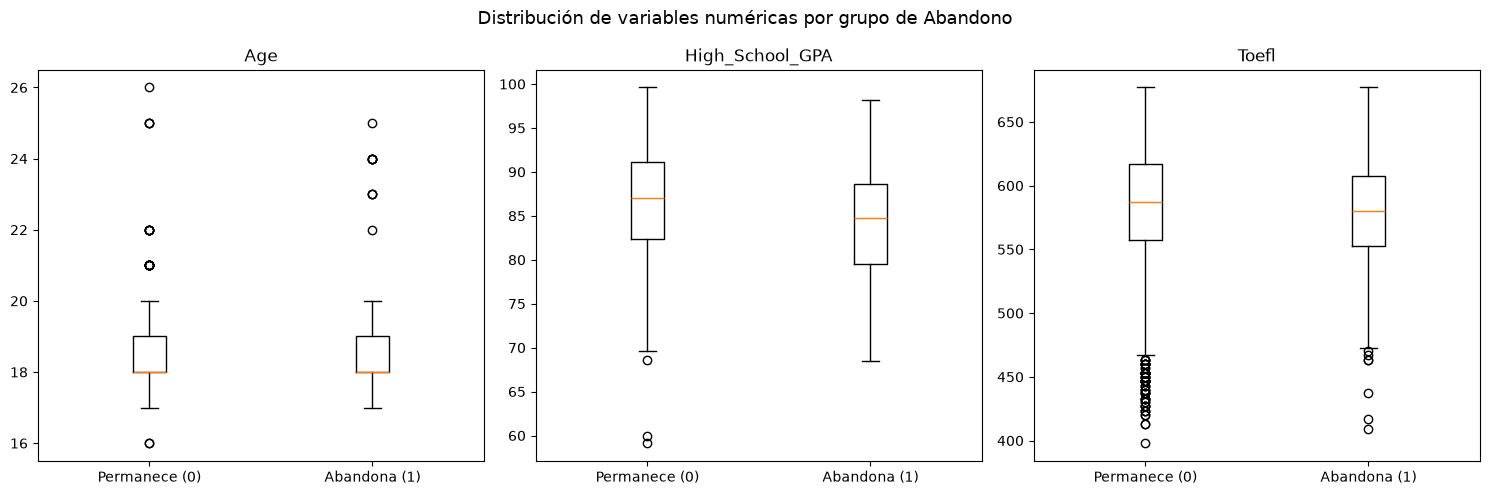

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Distribución de variables numéricas por grupo de Abandono", fontsize=13)

for ax, col in zip(axes, ['Age', 'High_School_GPA', 'Toefl']):
    ax.boxplot(
        [data.loc[data['Abandono'] == 0, col],
         data.loc[data['Abandono'] == 1, col]],
        tick_labels=['Permanece (0)', 'Abandona (1)']
    )
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 2.8 Matriz de correlación

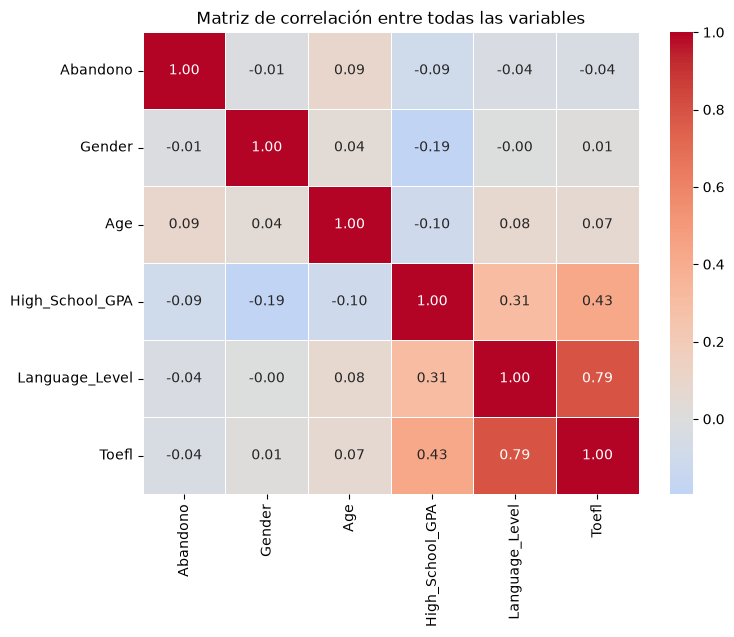

In [18]:
plt.figure(figsize=(8, 6))
plt.title("Matriz de correlación entre todas las variables")
sns.heatmap(data.corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.5)
plt.show()

> **Hallazgo crítico:** `Language_Level` y `Toefl` tienen una correlación de **0.79** entre sí.
> Esto indica **multicolinealidad**

## Paso 3 — Preprocesamiento de datos

### 3.1 Eliminar duplicados

In [19]:
print("Registros antes:", data.shape[0])
data = data.drop_duplicates().reset_index(drop=True)
print("Registros después de eliminar duplicados:", data.shape[0])
print("Duplicados eliminados:", 6620 - data.shape[0])

Registros antes: 6620
Registros después de eliminar duplicados: 6569
Duplicados eliminados: 51


> Los 51 registros duplicados son filas con valores **idénticos en todas las columnas**.
> Mantenerlos sobrepondería esas observaciones en el entrenamiento, sesgando el modelo.

## Paso 4 — Selección de variables y construcción del modelo

### 4.1 ¿Por qué no incluimos `Language_Level`?

Ya lo vimos en la matriz de correlación: tiene **r = 0.79** con `Toefl`.
Verifiquemos numéricamente que excluirla prácticamente no afecta el AUC del modelo:

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def auc_con_variables(cols):
    X = data[cols]
    y = data['Abandono']
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    pipe = Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=500))])
    pipe.fit(Xtr, ytr)
    return round(roc_auc_score(yte, pipe.predict_proba(Xte)[:, 1]), 4)

print("AUC con Language_Level y Toefl:", auc_con_variables(['Gender','Age','High_School_GPA','Language_Level','Toefl']))
print("AUC sin Language_Level         :", auc_con_variables(['Gender','Age','High_School_GPA','Toefl']))
print()
print("→ La diferencia es mínima. Elegimos el modelo MÁS SIMPLE e interpretable.")

AUC con Language_Level y Toefl: 0.6374
AUC sin Language_Level         : 0.6345

→ La diferencia es mínima. Elegimos el modelo MÁS SIMPLE e interpretable.


### 4.2 Separar variables predictoras (X) y objetivo (y)

In [21]:
feature_cols = ['Gender', 'Age', 'High_School_GPA', 'Toefl']
target_col   = 'Abandono'

X = data[feature_cols].copy()
y = data[target_col].astype(int).copy()

print("Variables predictoras (X):", list(X.columns))
print("Variable objetivo      (y):", target_col)
print("Shape X:", X.shape, "| Shape y:", y.shape)

Variables predictoras (X): ['Gender', 'Age', 'High_School_GPA', 'Toefl']
Variable objetivo      (y): Abandono
Shape X: (6569, 4) | Shape y: (6569,)


### 4.3 Dividir en entrenamiento y prueba

In [22]:
# stratify=y garantiza que ambos conjuntos tengan la misma proporción de abandono (~4.4%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Tasa abandono → train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

X_train: (4598, 4) | X_test: (1971, 4)
Tasa abandono → train: 0.044 | test: 0.044


### 4.4 Escalar variables: comparación estandarización vs normalización

Las variables tienen escalas muy distintas:
- `Age`: 16–26
- `GPA`: 59–99
- `Toefl`: 398–677

Si no escalamos, las variables con valores grandes dominan el modelo. Existen dos opciones comunes:
- **Estandarización (`StandardScaler`):** deja cada variable con media 0 y desviación estándar 1.
- **Normalización (`MinMaxScaler`):** lleva cada variable al rango [0, 1].

Como vimos en clase, muchos modelos funcionan con ambas y **conviene compararlas**. La recomendación general es:
- **Clustering, PCA y modelos lineales** (como esta regresión logística) → empezar con **estandarización**.
- **Clasificación bayesiana, árboles de decisión y redes neuronales** → **no** requieren escalamiento.

Como la regresión logística es un modelo lineal, parto de la estandarización, pero comparo las tres opciones
empíricamente —estandarización, normalización y **sin escalar**— para que la decisión quede justificada.

In [23]:
# Comparamos las tres opciones de forma justa: mismo split y modelo, y
# evaluamos cada una en SU umbral de mínimo costo (que es como se usará el modelo)
from sklearn.preprocessing import MinMaxScaler

def comparar_escalador(scaler):
    if scaler is None:                       # opción "sin escalar"
        Xtr, Xte = X_train, X_test
    else:
        sc = scaler.fit(X_train)             # se ajusta SOLO con train (sin fuga de datos)
        Xtr, Xte = sc.transform(X_train), sc.transform(X_test)
    lr = LogisticRegression(max_iter=500, solver='lbfgs').fit(Xtr, y_train)
    score = lr.predict_proba(Xte)[:, 1]
    auc = roc_auc_score(y_test, score)
    # buscamos el umbral de minimo costo para cada opcion
    mejor = None
    for th in np.linspace(0.01, 0.99, 199):
        yp = (score >= th).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
        costo = 10_000 * fp + 80_000 * fn
        if mejor is None or costo < mejor['Costo mínimo']:
            mejor = {'Umbral óptimo': round(th, 3), 'Costo mínimo': costo, 'TP': tp}
    return round(auc, 4), mejor

resultados = []
for nombre, sc in [('Sin escalar', None),
                   ('StandardScaler (estandarización)', StandardScaler()),
                   ('MinMaxScaler (normalización)', MinMaxScaler())]:
    auc, mejor = comparar_escalador(sc)
    resultados.append({'Opción': nombre, 'AUC': auc, **mejor})

comp_scalers = pd.DataFrame(resultados)
display(comp_scalers)
print()
print("→ Sin escalar y StandardScaler dan casi lo mismo: en una regresión logística escalar")
print("  casi no cambia las predicciones. Elijo StandardScaler por INTERPRETABILIDAD (deja los")
print("  coeficientes en la misma escala para compararlos) y porque es la opción recomendada")
print("  para modelos lineales.")

,Opción,AUC,Umbral óptimo,Costo mínimo,TP
0,Sin escalar,0.6347,0.094,6350000,16
1,StandardScaler (estandarización),0.6345,0.089,6350000,18
2,MinMaxScaler (normalización),0.6338,0.089,6510000,11



→ Sin escalar y StandardScaler dan casi lo mismo: en una regresión logística escalar
  casi no cambia las predicciones. Elijo StandardScaler por INTERPRETABILIDAD (deja los
  coeficientes en la misma escala para compararlos) y porque es la opción recomendada
  para modelos lineales.


> La comparación deja ver un punto importante: en una regresión logística, **escalar casi no cambia el
> resultado**. Sin escalar y con `StandardScaler` se obtiene prácticamente el mismo AUC (~0.635) y el mismo
> costo mínimo ($6,350,000); la normalización queda un poco por detrás. 

In [24]:
scaler = StandardScaler()
scaler.fit(X_train)                      # aprende media y desv. estándar SOLO del train

X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Datos de entrenamiento escalados (primeras 5 filas):")
pd.DataFrame(X_train_scaled, columns=feature_cols).head()

Datos de entrenamiento escalados (primeras 5 filas):


,Gender,Age,High_School_GPA,Toefl
0,-1.070323,-0.369867,1.509007,-0.214299
1,-1.070323,-0.369867,1.351401,0.321722
2,-1.070323,-0.369867,0.487940,0.484858
3,0.934298,-0.369867,1.620768,0.554774
4,0.934298,1.149926,-0.297669,-1.239729


### 4.5 Entrenar el modelo de Regresión Logística

In [25]:
logmodel = LogisticRegression(max_iter=500, solver='lbfgs')
logmodel.fit(X_train_scaled, y_train)
print(logmodel)

LogisticRegression(max_iter=500)


## Paso 5 — Coeficientes e interpretación del modelo

### 5.1 Coeficientes β y Odds Ratio

Cada coeficiente β indica cómo cambia el **log-odds** de abandono cuando la variable sube en una unidad (escalada):
- **β > 0** → aumenta la probabilidad de abandono
- **β < 0** → disminuye la probabilidad de abandono

El **Odds Ratio = e^β** dice cuánto se multiplican los odds de abandono.

In [26]:
coef_df = pd.DataFrame({
    'Variable'           : feature_cols,
    'Coeficiente β'      : logmodel.coef_[0],
    'Odds Ratio (1 DE)'  : np.exp(logmodel.coef_[0]),
    'Odds Ratio (1 unidad original)': np.exp(logmodel.coef_[0] / scaler.scale_)
}).sort_values('Coeficiente β')

print(f"Intercepto (β₀): {logmodel.intercept_[0]:.3f}")
print()
display(coef_df.round(3))

Intercepto (β₀): -3.240



,Variable,Coeficiente β,Odds Ratio (1 DE),Odds Ratio (1 unidad original)
2,High_School_GPA,-0.458,0.633,0.924
0,Gender,-0.217,0.805,0.647
3,Toefl,-0.070,0.933,0.998
1,Age,0.280,1.323,1.530


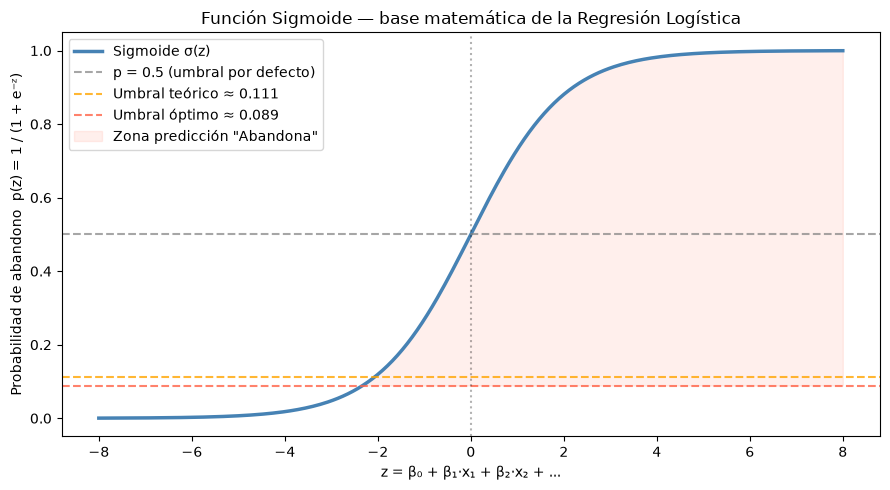

In [27]:
# Visualización de la función sigmoide (base teórica del modelo)
z = np.linspace(-8, 8, 300)
sigmoid = 1 / (1 + np.exp(-z))

umbral_teorico = 10_000 / (10_000 + 80_000)   # C_FP / (C_FP + C_FN) ≈ 0.111

plt.figure(figsize=(9, 5))
plt.plot(z, sigmoid, color='steelblue', linewidth=2.5, label='Sigmoide σ(z)')
plt.axhline(0.5,             linestyle='--', color='gray',   alpha=0.7, label='p = 0.5 (umbral por defecto)')
plt.axhline(umbral_teorico,  linestyle='--', color='orange', alpha=0.8, label=f'Umbral teórico ≈ {umbral_teorico:.3f}')
plt.axhline(0.089,           linestyle='--', color='tomato', alpha=0.8, label='Umbral óptimo ≈ 0.089')
plt.axvline(0, linestyle=':', color='black', alpha=0.3)
plt.fill_between(z, sigmoid, 0.089, where=(sigmoid >= 0.089), alpha=0.1, color='tomato',
                 label='Zona predicción "Abandona"')
plt.xlabel("z = β₀ + β₁·x₁ + β₂·x₂ + ...")
plt.ylabel("Probabilidad de abandono  p(z) = 1 / (1 + e⁻ᶻ)")
plt.title("Función Sigmoide — base matemática de la Regresión Logística")
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Interpretación de cada variable:**
- **`High_School_GPA` (β = −0.46):** el predictor más fuerte. Cada punto más de promedio reduce los odds de abandono en ≈7.6 %.
- **`Age` (β = +0.28):** cada año más de edad multiplica los odds de abandono por ≈1.53 (+53 %).
- **`Gender` (β = −0.22):** los estudiantes con Gender = 1 tienen ≈35 % menos odds de abandonar.
- **`Toefl` (β = −0.07):** efecto protector pero pequeño; 100 puntos más de TOEFL reducen los odds ≈15 %.

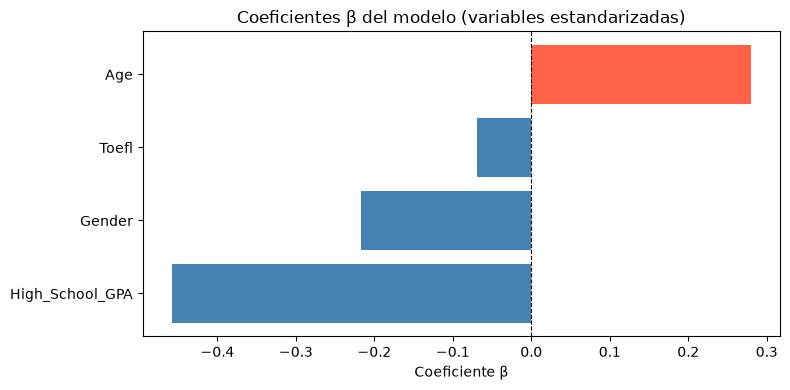

In [28]:
# Gráfica de coeficientes (equivalente al barplot del maestro)
plt.figure(figsize=(8, 4))
plt.title("Coeficientes β del modelo (variables estandarizadas)")
colors = ['tomato' if c > 0 else 'steelblue' for c in coef_df['Coeficiente β']]
plt.barh(coef_df['Variable'], coef_df['Coeficiente β'], color=colors)
plt.axvline(0, linestyle='--', color='black', linewidth=0.8)
plt.xlabel("Coeficiente β")
plt.tight_layout()
plt.show()

### 5.2 Predicciones y probabilidades

In [29]:
predicciones  = logmodel.predict(X_test_scaled)
probabilidades = logmodel.predict_proba(X_test_scaled)

print("Mostrando probabilidades para los primeros 5 ejemplos del set de Testing")
print("Columna 0 = P(permanece), Columna 1 = P(abandona)")
probabilidades[:5]

Mostrando probabilidades para los primeros 5 ejemplos del set de Testing
Columna 0 = P(permanece), Columna 1 = P(abandona)


array([[0.96858683, 0.03141317],
       [0.97671709, 0.02328291],
       [0.97806892, 0.02193108],
       [0.97313668, 0.02686332],
       [0.97717542, 0.02282458]])

In [30]:
print("Forma de la matriz de probabilidades:", probabilidades.shape)

Forma de la matriz de probabilidades: (1971, 2)


In [31]:
# Extraemos solo la probabilidad de abandono (clase 1)
y_scores = probabilidades[:, 1]

## Paso 6 — Evaluación del modelo

### 6.1 Reporte de clasificación (umbral por defecto = 0.5)

In [32]:
print(classification_report(y_test, predicciones,
      target_names=['Permanece (0)', 'Abandona (1)']))

               precision    recall  f1-score   support

Permanece (0)       0.96      1.00      0.98      1885
 Abandona (1)       1.00      0.01      0.02        86

     accuracy                           0.96      1971
    macro avg       0.98      0.51      0.50      1971
 weighted avg       0.96      0.96      0.94      1971



>  **Paradoja de la accuracy:** la accuracy es ≈95.7 % pero el modelo apenas detecta abandonos con el umbral 0.5.
> Esto ocurre porque la clase está muy desbalanceada (4.4 % abandona).
> Un modelo que siempre prediga "permanece" tendría la misma accuracy pero **cero utilidad**.
> Por eso necesitamos ajustar el umbral y evaluar con AUC y costo.

### 6.2 Comparación con el Modelo Nulo (baseline)

In [33]:
C_FP = 10_000   # costo de un Falso Positivo
C_FN = 80_000   # costo de un Falso Negativo

def evaluar_umbral(y_true, y_score, th):
    y_pred = (y_score >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'Umbral'        : th,
        'TP'            : tp,
        'FP'            : fp,
        'TN'            : tn,
        'FN'            : fn,
        'Precisión'     : round(precision_score(y_true, y_pred, zero_division=0), 3),
        'Recall'        : round(recall_score(y_true, y_pred, zero_division=0), 3),
        'Especificidad' : round(tn / (tn + fp), 3),
        'Accuracy'      : round(accuracy_score(y_true, y_pred), 3),
        'F1'            : round(f1_score(y_true, y_pred, zero_division=0), 3),
        'Costo Total'   : C_FP * fp + C_FN * fn
    }

# Modelo nulo: siempre predice la clase mayoritaria (Permanece = 0)
y_nulo = np.zeros(len(y_test), dtype=int)

print("=== Modelo NULO (siempre predice 'Permanece') ===")
print(classification_report(y_test, y_nulo,
      target_names=['Permanece (0)', 'Abandona (1)'],
      zero_division=0))

print("=== Modelo LOGÍSTICO (umbral 0.5) ===")
print(classification_report(y_test, predicciones,
      target_names=['Permanece (0)', 'Abandona (1)']))

# Tabla resumen comparativa
comp = pd.DataFrame({
    'Métrica': ['Accuracy', 'Recall abandono', 'Precisión abandono', 'AUC ROC', 'Costo Total'],
    'Modelo Nulo': [
        round(accuracy_score(y_test, y_nulo), 4),
        0.000,
        0.000,
        0.500,
        f"${C_FN * int((y_test==1).sum()):,.0f}"
    ],
    'Modelo Logístico (0.5)': [
        round(accuracy_score(y_test, predicciones), 4),
        round(recall_score(y_test, predicciones, zero_division=0), 3),
        round(precision_score(y_test, predicciones, zero_division=0), 3),
        round(roc_auc_score(y_test, y_scores), 4),
        f"${evaluar_umbral(y_test, y_scores, 0.5)['Costo Total']:,.0f}"
    ]
})
display(comp)

=== Modelo NULO (siempre predice 'Permanece') ===
               precision    recall  f1-score   support

Permanece (0)       0.96      1.00      0.98      1885
 Abandona (1)       0.00      0.00      0.00        86

     accuracy                           0.96      1971
    macro avg       0.48      0.50      0.49      1971
 weighted avg       0.91      0.96      0.94      1971

=== Modelo LOGÍSTICO (umbral 0.5) ===
               precision    recall  f1-score   support

Permanece (0)       0.96      1.00      0.98      1885
 Abandona (1)       1.00      0.01      0.02        86

     accuracy                           0.96      1971
    macro avg       0.98      0.51      0.50      1971
 weighted avg       0.96      0.96      0.94      1971



,Métrica,Modelo Nulo,Modelo Logístico (0.5)
0,Accuracy,0.9564,0.9569
1,Recall abandono,0.0,0.012
2,Precisión abandono,0.0,1.0
3,AUC ROC,0.5,0.6345
4,Costo Total,"$6,880,000","$6,800,000"


In [ ]:
print(f"Exactitud del modelo nulo: {accuracy_score(y_test, y_nulo)*100:.1f}%")

Exactitud del modelo nulo: 95.6%


> **El modelo nulo tiene accuracy idéntica al logístico con umbral 0.5 (≈95.6 %)**, pero detecta 0 abandonos.
> Esto demuestra que **accuracy no es una métrica válida** cuando las clases están desbalanceadas.
> El AUC (0.635 vs 0.500) y el costo total son las métricas que revelan el valor real del modelo.

### 6.3 Accuracy

In [34]:
print("Accuracy del modelo:", round(accuracy_score(y_test, predicciones), 4))

Accuracy del modelo: 0.9569


### 6.4 Matriz de confusión (umbral 0.5)

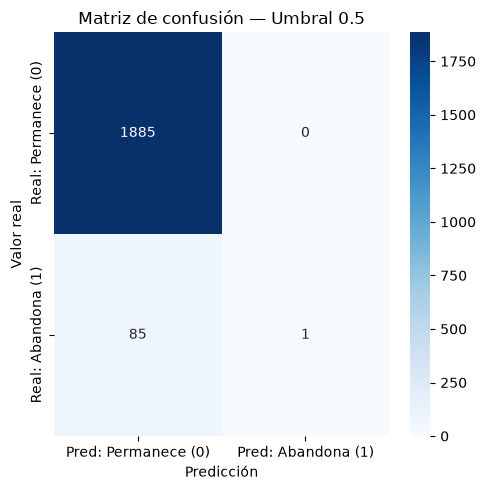

In [35]:
cm = confusion_matrix(y_test, predicciones)
plt.figure(figsize=(5, 5))
plt.title("Matriz de confusión — Umbral 0.5")
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            yticklabels=['Real: Permanece (0)', 'Real: Abandona (1)'],
            xticklabels=['Pred: Permanece (0)', 'Pred: Abandona (1)'])
plt.ylabel("Valor real")
plt.xlabel("Predicción")
plt.tight_layout()
plt.show()

### 6.5 Curva ROC

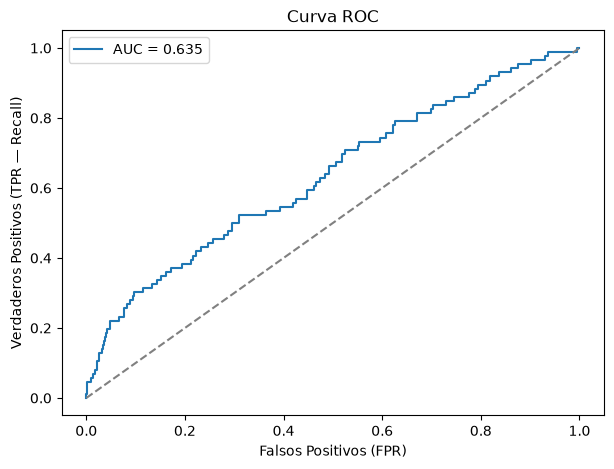

In [36]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_scores)
roc_auc = roc_auc_score(y_test, y_scores)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("Falsos Positivos (FPR)")
plt.ylabel("Verdaderos Positivos (TPR — Recall)")
plt.title("Curva ROC")
plt.legend()
plt.show()

In [60]:
# Cuántas veces supera al azar
print(f"El modelo es {ap/y_test.mean():.1f}x mejor que el azar (AP={ap:.3f} vs tasa base={y_test.mean():.3f})")

El modelo es 2.7x mejor que el azar (AP=0.117 vs tasa base=0.044)


> **AUC = 0.635:** el modelo discrimina mejor que el azar (0.5), pero es una capacidad **moderada**.
> En el 63.5 % de los pares (un estudiante que abandona vs uno que permanece), el modelo asigna mayor probabilidad al que abandona.
> **Limitación:** una AUC moderada implica errores frecuentes. Con solo 4 variables disponibles el modelo no captura factores determinantes del abandono como situación económica, motivación o asistencia. Una discriminación moderada **no elimina** esta limitación: los patrones encontrados deben tratarse como hipótesis, no como verdad, hasta validarlos con variables adicionales.

### 6.6 Curva Precisión-Recall

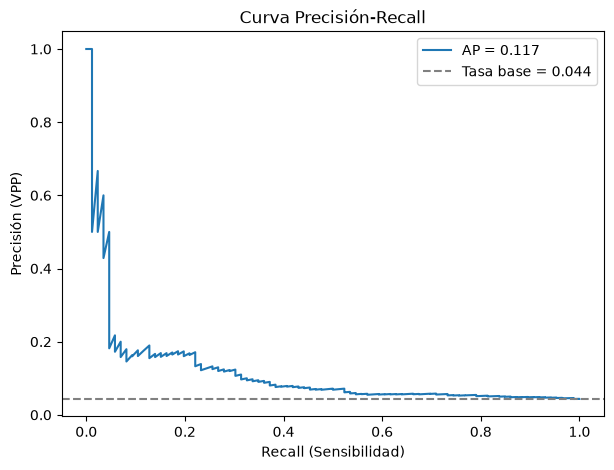

In [37]:
ap = average_precision_score(y_test, y_scores)
precision_c, recall_c, pr_thresholds = precision_recall_curve(y_test, y_scores)

plt.figure(figsize=(7, 5))
plt.plot(recall_c, precision_c, label=f'AP = {ap:.3f}')
plt.axhline(y_test.mean(), linestyle='--', color='gray',
            label=f'Tasa base = {y_test.mean():.3f}')
plt.xlabel("Recall (Sensibilidad)")
plt.ylabel("Precisión (VPP)")
plt.title("Curva Precisión-Recall")
plt.legend()
plt.show()

> **AP = 0.117 vs tasa base = 0.044:** el modelo encuentra **2.7 veces más** abandonos que escogiendo al azar.
> Esta curva es más informativa que ROC cuando las clases están desbalanceadas.

### 6.7 Precisión y Recall vs Umbral

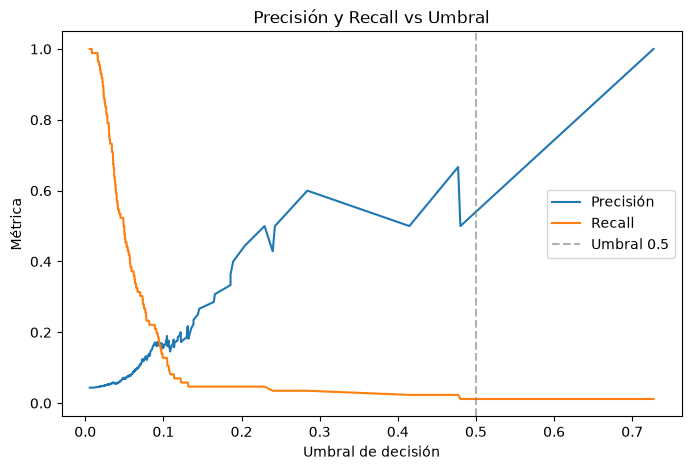

In [38]:
plt.figure(figsize=(8, 5))
plt.plot(pr_thresholds, precision_c[:-1], label='Precisión')
plt.plot(pr_thresholds, recall_c[:-1], label='Recall')
plt.axvline(0.5, linestyle='--', color='gray', alpha=0.6, label='Umbral 0.5')
plt.xlabel("Umbral de decisión")
plt.ylabel("Métrica")
plt.title("Precisión y Recall vs Umbral")
plt.legend()
plt.show()

> Con umbral 0.5 el Recall cae casi a cero: el modelo no clasifica a casi nadie como "abandona".
> Esto confirma que **0.5 no es el umbral correcto** para este problema.

## Paso 7 — Comparación de umbrales de referencia

In [39]:
# Incluimos umbrales bajos porque las probabilidades estimadas son pequeñas (clase rara)
umbrales_demo = [0.05, 0.10, 0.30, 0.50, 0.70]
tabla = pd.DataFrame([evaluar_umbral(y_test, y_scores, th) for th in umbrales_demo])
display(tabla)

,Umbral,TP,FP,TN,FN,Precisión,Recall,Especificidad,Accuracy,F1,Costo Total
0,0.05,41,556,1329,45,0.069,0.477,0.705,0.695,0.120,9160000
1,0.10,11,58,1827,75,0.159,0.128,0.969,0.933,0.142,6580000
2,0.30,2,2,1883,84,0.500,0.023,0.999,0.956,0.044,6740000
3,0.50,1,0,1885,85,1.000,0.012,1.000,0.957,0.023,6800000
4,0.70,1,0,1885,85,1.000,0.012,1.000,0.957,0.023,6800000


> Con umbral **0.50** la accuracy es alta pero solo detecta **1 de 86** abandonos (Recall = 1.2 %).
> Con umbral **0.05** detecta casi la mitad, pero genera 556 intervenciones innecesarias.
> El balance correcto lo define el **costo** → siguiente sección.

## Paso 8 — Selección del umbral óptimo por costos

**Fórmula:**
`Costo Total = C_FP × FP + C_FN × FN = $10,000 × FP + $80,000 × FN`

**Umbral teórico** = C_FP / (C_FP + C_FN) = 10,000 / 90,000 ≈ **0.111**
(Cuando un falso negativo es 8 veces más costoso que uno positivo, conviene bajar el umbral)

In [40]:
umbrales = np.linspace(0.01, 0.99, 199)
costos_df = pd.DataFrame([evaluar_umbral(y_test, y_scores, th) for th in umbrales])
costos_df.rename(columns={'Umbral': 'umbral'}, inplace=True)

best_idx          = costos_df['Costo Total'].idxmin()
umbral_min_costo  = float(costos_df.loc[best_idx, 'umbral'])
costo_minimo      = float(costos_df.loc[best_idx, 'Costo Total'])

print(f"Umbral teórico        = {C_FP / (C_FP + C_FN):.3f}")
print(f"Umbral óptimo hallado = {umbral_min_costo:.3f}")
print(f"Costo total mínimo    = ${costo_minimo:,.0f}")

Umbral teórico        = 0.111
Umbral óptimo hallado = 0.089
Costo total mínimo    = $6,350,000


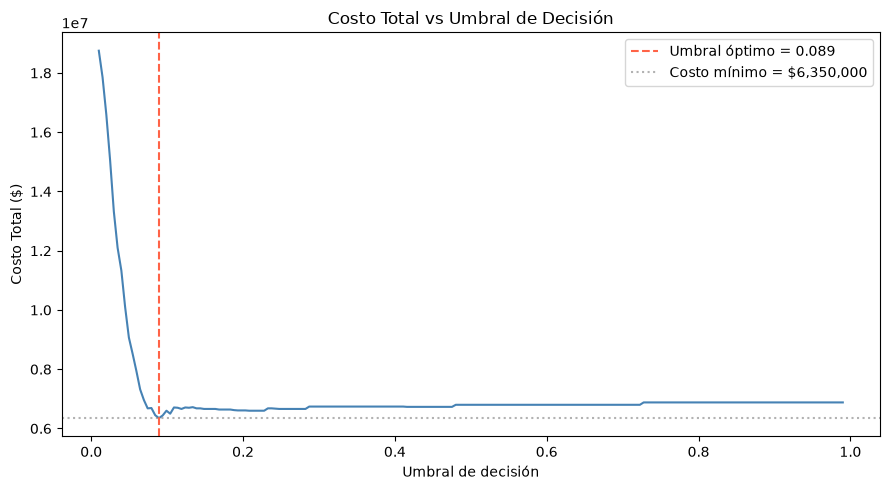

In [41]:
plt.figure(figsize=(9, 5))
plt.plot(costos_df['umbral'], costos_df['Costo Total'], color='steelblue')
plt.axvline(umbral_min_costo, linestyle='--', color='tomato',
            label=f'Umbral óptimo = {umbral_min_costo:.3f}')
plt.axhline(costo_minimo, linestyle=':', color='gray', alpha=0.6,
            label=f'Costo mínimo = ${costo_minimo:,.0f}')
plt.xlabel("Umbral de decisión")
plt.ylabel("Costo Total ($)")
plt.title("Costo Total vs Umbral de Decisión")
plt.legend()
plt.tight_layout()
plt.show()

In [42]:
print("Top 5 umbrales con menor costo:")
display(costos_df.nsmallest(5, 'Costo Total').round(3))

Top 5 umbrales con menor costo:


,umbral,TP,FP,TN,FN,Precisión,Recall,Especificidad,Accuracy,F1,Costo Total
16,0.089,18,91,1794,68,0.165,0.209,0.952,0.919,0.185,6350000
17,0.094,15,76,1809,71,0.165,0.174,0.960,0.925,0.169,6440000
15,0.084,19,109,1776,67,0.148,0.221,0.942,0.911,0.178,6450000
19,0.104,11,50,1835,75,0.180,0.128,0.973,0.937,0.150,6500000
18,0.099,11,60,1825,75,0.155,0.128,0.968,0.932,0.140,6600000


## Paso 9 — Criterios alternativos de selección de umbral

In [43]:
umbral_youden = float(roc_thresholds[np.argmax(tpr - fpr)])
umbral_f1     = float(costos_df.loc[costos_df['F1'].idxmax(), 'umbral'])

# Escenarios sin modelo (referencia)
costo_nadie = C_FN * int((y_test == 1).sum())    # no intervenimos a nadie
costo_todos = C_FP * int((y_test == 0).sum())    # intervenimos a todos

def resumen_umbral(criterio, umbral):
    r = evaluar_umbral(y_test, y_scores, umbral)
    r['Criterio'] = criterio
    return r

resumen = pd.DataFrame([
    resumen_umbral('Youden J', umbral_youden),
    resumen_umbral('Min Costo ✓', umbral_min_costo),
    resumen_umbral('F1 máximo', umbral_f1),
    resumen_umbral('Defecto 0.50', 0.50),
])[['Criterio','Umbral','TP','FP','TN','FN','Precisión','Recall','F1','Costo Total']]

display(resumen)
print()
print(f"Referencia — No intervenir a nadie  : ${costo_nadie:,.0f}")
print(f"Referencia — Intervenir a todos     : ${costo_todos:,.0f}")
print(f"Ahorro umbral óptimo vs no hacer nada: ${costo_nadie - costo_minimo:,.0f}  ({(costo_nadie-costo_minimo)/costo_nadie:.1%})")

,Criterio,Umbral,TP,FP,TN,FN,Precisión,Recall,F1,Costo Total
0,Youden J,0.048685,45,583,1302,41,0.072,0.523,0.126,9110000
1,Min Costo ✓,0.089192,18,91,1794,68,0.165,0.209,0.185,6350000
2,F1 máximo,0.089192,18,91,1794,68,0.165,0.209,0.185,6350000
3,Defecto 0.50,0.500000,1,0,1885,85,1.000,0.012,0.023,6800000



Referencia — No intervenir a nadie  : $6,880,000
Referencia — Intervenir a todos     : $18,850,000
Ahorro umbral óptimo vs no hacer nada: $530,000  (7.7%)


## Paso 10 — Matriz de confusión con el umbral óptimo

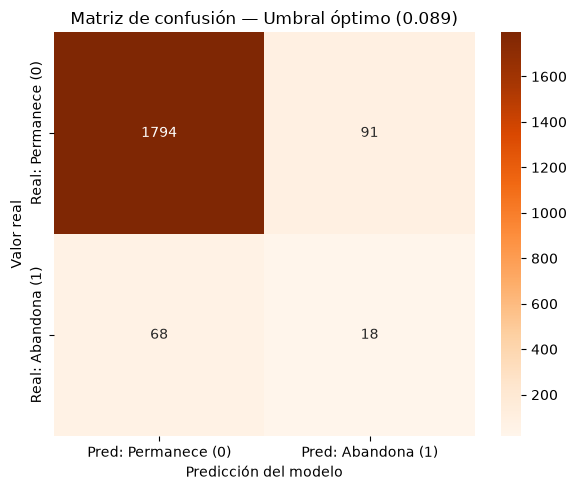

TP (detectados a tiempo)       : 18  →  ahorro = $1,440,000
FP (intervenciones innecesarias): 91  →  costo  = $910,000
FN (abandonos no detectados)   : 68  →  pérdida = $5,440,000
TN (correctamente ignorados)   : 1794

Estudiantes marcados como riesgo: 109 (5.5% del total de prueba)


In [44]:
y_pred_opt = (y_scores >= umbral_min_costo).astype(int)

cm_opt = confusion_matrix(y_test, y_pred_opt)
plt.figure(figsize=(6, 5))
plt.title(f"Matriz de confusión — Umbral óptimo ({umbral_min_costo:.3f})")
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Oranges',
            yticklabels=['Real: Permanece (0)', 'Real: Abandona (1)'],
            xticklabels=['Pred: Permanece (0)', 'Pred: Abandona (1)'])
plt.ylabel("Valor real")
plt.xlabel("Predicción del modelo")
plt.tight_layout()
plt.show()

tn_o, fp_o, fn_o, tp_o = cm_opt.ravel()
print(f"TP (detectados a tiempo)       : {tp_o}  →  ahorro = ${C_FN * tp_o:,.0f}")
print(f"FP (intervenciones innecesarias): {fp_o}  →  costo  = ${C_FP * fp_o:,.0f}")
print(f"FN (abandonos no detectados)   : {fn_o}  →  pérdida = ${C_FN * fn_o:,.0f}")
print(f"TN (correctamente ignorados)   : {tn_o}")
print(f"\nEstudiantes marcados como riesgo: {tp_o + fp_o} ({(tp_o+fp_o)/len(y_test)*100:.1f}% del total de prueba)")

In [62]:
# Proporción de abandonos no detectados 
print(f"Abandonos no detectados: {fn_o}/{fn_o+tp_o} = {fn_o/(fn_o+tp_o)*100:.0f}%")

Abandonos no detectados: 68/86 = 79%


## Paso 11 — Sensibilidad del umbral según costos

In [45]:
print("¿Qué pasa si el costo de perder un estudiante cambia?")
print("(C_FP fijo en $10,000, C_FN variable)")
print()

sensibilidad = []
for c_fn in [20_000, 40_000, 80_000, 120_000, 160_000]:
    costos = [10_000*r['FP'] + c_fn*r['FN']
              for _, r in costos_df.iterrows()]
    idx = np.argmin(costos)
    sensibilidad.append({
        'C_FN': f'${c_fn:,.0f}',
        'Umbral óptimo': round(umbrales[idx], 3),
        'Costo mínimo': f'${min(costos):,.0f}'
    })

display(pd.DataFrame(sensibilidad))
print()
print("→ El umbral óptimo se mantiene estable entre $80K y $120K: la decisión es robusta.")

¿Qué pasa si el costo de perder un estudiante cambia?
(C_FP fijo en $10,000, C_FN variable)



,C_FN,Umbral óptimo,Costo mínimo
0,"$20,000",0.208,"$1,680,000"
1,"$40,000",0.208,"$3,320,000"
2,"$80,000",0.089,"$6,350,000"
3,"$120,000",0.089,"$9,070,000"
4,"$160,000",0.074,"$11,640,000"



→ El umbral óptimo se mantiene estable entre $80K y $120K: la decisión es robusta.


## Paso 12 — Curva de Aprendizaje del modelo

La curva de aprendizaje muestra cómo varía el rendimiento del modelo a medida que aumenta el tamaño del conjunto de entrenamiento.
Sirve para diagnosticar **sobreajuste** (overfitting) o **subajuste** (underfitting) y saber si más datos mejorarían el modelo.

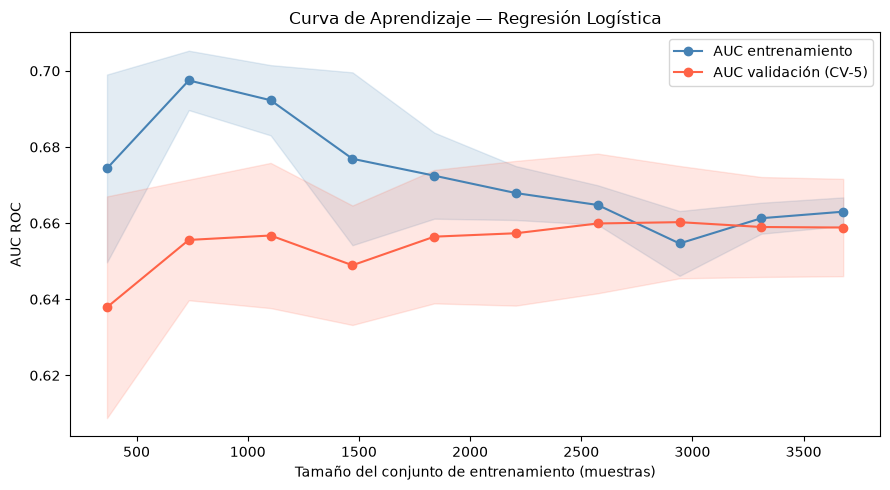

In [46]:
from sklearn.model_selection import learning_curve
from sklearn.pipeline import Pipeline

# Pipeline completo para la curva de aprendizaje
pipe_lc = Pipeline([
    ('scaler', StandardScaler()),
    ('lr',     LogisticRegression(max_iter=500, solver='lbfgs'))
])

tamanios = np.linspace(0.10, 1.0, 10)   # del 10% al 100% del train

train_sizes, train_scores, val_scores = learning_curve(
    pipe_lc, X_train, y_train,
    train_sizes=tamanios,
    cv=5,                        # validación cruzada de 5 pliegues
    scoring='roc_auc',
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_mean, 'o-', color='steelblue', label='AUC entrenamiento')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                 alpha=0.15, color='steelblue')
plt.plot(train_sizes, val_mean, 'o-', color='tomato', label='AUC validación (CV-5)')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                 alpha=0.15, color='tomato')
plt.xlabel("Tamaño del conjunto de entrenamiento (muestras)")
plt.ylabel("AUC ROC")
plt.title("Curva de Aprendizaje — Regresión Logística")
plt.legend()
plt.tight_layout()
plt.show()

> **Diagnóstico:**
> - Si las curvas de entrenamiento y validación **convergen** en un valor similar → el modelo no está sobreajustado.
> - Si la brecha es grande (train alto, val bajo) → sobreajuste; si ambas son bajas → subajuste.
> - Una curva de validación que todavía sube al llegar al 100 % indica que **más datos mejorarían el modelo**.

## Paso 13 — Estudiantes con mayor probabilidad de abandono (Top 20)

In [47]:
# Creamos un DataFrame con los datos de prueba + probabilidades predichas
riesgo_df = X_test.copy().reset_index(drop=True)
riesgo_df['P_abandono'] = y_scores
riesgo_df['Real'] = y_test.values
riesgo_df['Prediccion'] = y_pred_opt

top20 = riesgo_df.sort_values('P_abandono', ascending=False).head(20)
top20['P_abandono'] = top20['P_abandono'].round(4)
print("Top 20 estudiantes con mayor probabilidad estimada de abandono:")
display(top20)
print()
print(f"De estos 20, el modelo identificó correctamente como riesgo a: {(top20['Prediccion']==1).sum()}")
print(f"De los 20 de mayor probabilidad, cuántos realmente abandonaron: {(top20['Real']==1).sum()}")

Top 20 estudiantes con mayor probabilidad estimada de abandono:


,Gender,Age,High_School_GPA,Toefl,P_abandono,Real,Prediccion
1490,0,25,74.372,497,0.7271,1,1
1363,0,20,59.133,583,0.4801,0,1
49,1,24,75.120,590,0.4772,1,1
1681,0,25,90.000,550,0.4148,0,1
282,0,24,90.770,607,0.2843,1,1
840,0,20,75.770,423,0.2427,0,1
1746,0,22,83.260,591,0.2399,0,1
1876,0,23,88.830,617,0.2294,1,1
1211,1,18,60.000,537,0.2042,0,1
589,1,20,71.460,560,0.1893,0,1



De estos 20, el modelo identificó correctamente como riesgo a: 20
De los 20 de mayor probabilidad, cuántos realmente abandonaron: 4


> Esta lista es el **producto operativo** del modelo: el área de tutorías puede ordenarla por probabilidad  
> y contactar primero a los estudiantes con mayor P_abandono para intervenir de forma prioritaria.